# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nancy121205/flyrank/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

Research question: Can content metadata and measurements from the preceding 30-day period help prioritize pages for human review when recent search impressions have declined?
The decision supported is which pages a content reviewer should investigate first. The output is a ranked review queue, not an automatic content-change system. The target identifies pages whose latest 30-day impressions fell by more than 20% compared with the preceding 30-day period, as represented by the dataset’s trend_direction == "down" label.
The goal is to measure whether a model ranks these observed declines more usefully than a transparent freshness-first heuristic.

In [13]:
%pip -q install pandas numpy scikit-learn matplotlib

In [14]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, StratifiedShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42
TOP_K = 20

OUTPUT_DIR = Path("capstone_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python libraries ready.")
print("scikit-learn:", sklearn.__version__)
print("Output folder:", OUTPUT_DIR.resolve())

Python libraries ready.
scikit-learn: 1.6.1
Output folder: /content/capstone_artifacts


## 2. Data

The analysis uses the public anonymized FlyRank starter dataset, content_refresh_anonymized.csv. The supplied data dictionary describes one row per content item, 44 raw columns, approximately 30,000 rows, and 32 pseudonymized clients. The dataset includes content metadata, keyword context, previous- and latest-30-day measurements, and trailing-90-day performance summaries.





For the target, trend_direction is used to identify the observed decline category. The feature set is deliberately limited to content metadata and prior-window measurements. It excludes identifiers, the target and its derived percentage, the latest-30-day target inputs, and trailing-90-day outcome metrics that overlap the target period.
The CSV column names describe the measurement windows, but do not by themselves establish the absolute calendar dates of the export. The paper will not claim specific calendar dates without verifying the release documentation.

In [15]:
DATA_URL = (
    "https://raw.githubusercontent.com/flyrank-bih/"
    "flyrank-ml-internship-starter/main/data/raw/"
    "content_refresh_anonymized.csv"
)

try:
    df = pd.read_csv(DATA_URL)
    DATA_SOURCE = "Public FlyRank anonymized starter CSV"
    print("Loaded starter CSV from the public source.")

except Exception as download_error:
    print("Automatic loading failed:", type(download_error).__name__)
    print("Upload content_refresh_anonymized.csv to continue.")

    try:
        from google.colab import files
    except ImportError as import_error:
        raise RuntimeError(
            "Automatic loading failed. Open this notebook in Google Colab "
            "or place the CSV in the notebook's working directory."
        ) from download_error

    uploaded = files.upload()

    if not uploaded:
        raise RuntimeError(
            "No file was uploaded. Upload content_refresh_anonymized.csv."
        )

    uploaded_name = next(iter(uploaded.keys()))
    df = pd.read_csv(uploaded_name)
    DATA_SOURCE = "Uploaded anonymized starter CSV"

df.columns = df.columns.astype(str).str.strip()

required_columns = {"client_id", "trend_direction"}
missing_required = required_columns - set(df.columns)

if missing_required:
    raise ValueError(
        f"Required columns missing: {sorted(missing_required)}. "
        "Check that you uploaded the original content_refresh_anonymized.csv."
    )

print("\nDATA CHECK")
print("Source:", DATA_SOURCE)
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))
print("Distinct client groups:", df["client_id"].nunique())
print("Has content_id:", "content_id" in df.columns)
print("Has trend_direction:", "trend_direction" in df.columns)
print("Has trend_pct:", "trend_pct" in df.columns)

print("\nColumn names:")
print(df.columns.tolist())

print("\nTarget category counts:")
print(
    df["trend_direction"]
    .astype("string")
    .str.strip()
    .str.lower()
    .value_counts(dropna=False)
    .to_string()
)

Loaded starter CSV from the public source.

DATA CHECK
Source: Public FlyRank anonymized starter CSV
Rows: 30,000
Columns: 44
Distinct client groups: 32
Has content_id: True
Has trend_direction: True
Has trend_pct: True

Column names:
['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_

In [16]:
# Known target categories from the starter data dictionary.
VALID_DIRECTIONS = {"new", "flat", "up", "down", "stable"}

directions = (
    df["trend_direction"]
    .astype("string")
    .str.strip()
    .str.lower()
)

valid_target_mask = directions.isin(VALID_DIRECTIONS)

unknown_count = int((~valid_target_mask).sum())

if valid_target_mask.sum() == 0:
    raise ValueError(
        "No recognized trend_direction values were found. "
        "Check the target category counts printed in Cell 1."
    )

# Keep rows with a recognized observed target.
df_labeled = df.loc[valid_target_mask].copy().reset_index(drop=True)

# Positive label = the observed 'down' category.
y = (
    df_labeled["trend_direction"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("down")
    .astype(int)
)

if y.nunique() != 2:
    raise ValueError(
        "The labeled data must contain both down and not-down examples. "
        "Review the target distribution before training."
    )

# Only use metadata and preceding-window features.
# Deliberately excluded:
# - content_id and client_id: identifiers
# - trend_direction and trend_pct: target / target-derived values
# - latest-30-day outcome measurements
# - trailing-90-day performance metrics that overlap the target period
# - derived performance rates and tiers

FEATURE_CANDIDATES = [
    # Keyword context
    "search_volume",
    "competition",
    "competition_level",
    "cpc",

    # Content metadata
    "content_type",
    "main_intent",
    "word_count",
    "char_count",
    "content_age_days",
    "age_tier_order",
    "days_since_last_update",
    "freshness_tier",
    "word_count_tier",
    "char_count_tier",

    # Historical values from the 30-day period before the target window
    "impressions_prev_30d",
    "clicks_prev_30d",
    "sessions_prev_30d",
]

FEATURES = [
    col for col in FEATURE_CANDIDATES
    if col in df_labeled.columns
]

if not FEATURES:
    raise ValueError(
        "None of the expected feature columns were found. "
        "Check the CSV schema printed in Cell 1."
    )

# Explicit leakage / identifier guard.
FORBIDDEN_FEATURES = {
    "content_id",
    "client_id",
    "trend_direction",
    "trend_pct",
    "impressions_last_30d",
    "clicks_last_30d",
    "sessions_last_30d",
    "impressions_90d",
    "clicks_90d",
    "pageviews_90d",
    "sessions_90d",
    "users_90d",
    "engaged_sessions_90d",
    "ai_sessions_90d",
    "scroll_events_90d",
    "days_with_impressions",
    "days_with_sessions",
    "ctr",
    "avg_position",
    "engagement_rate",
    "scroll_rate",
    "ai_traffic_pct",
    "impression_tier",
    "position_tier",
    "provider_used",
    "model_used",
}

unsafe_selected = set(FEATURES) & FORBIDDEN_FEATURES

if unsafe_selected:
    raise ValueError(
        f"Leakage or identifier columns found in features: {sorted(unsafe_selected)}"
    )

X = df_labeled[FEATURES].copy()
y = y.reset_index(drop=True)

print("LABEL DEFINITION")
print("1 = trend_direction == 'down'")
print("0 = another recognized direction")
print("Rows excluded due to unknown/missing target:", unknown_count)

print("\nLabel counts:")
print(y.value_counts().rename(index={0: "not_down", 1: "down"}).to_string())

print("\nTarget-positive rate:", round(float(y.mean()), 4))
print("\nSelected features:")
for col in FEATURES:
    print("-", col)

print("\nFeature matrix shape:", X.shape)

LABEL DEFINITION
1 = trend_direction == 'down'
0 = another recognized direction
Rows excluded due to unknown/missing target: 0

Label counts:
trend_direction
down        16262
not_down    13738

Target-positive rate: 0.5421

Selected features:
- search_volume
- competition
- competition_level
- cpc
- content_type
- main_intent
- word_count
- char_count
- content_age_days
- age_tier_order
- days_since_last_update
- freshness_tier
- word_count_tier
- char_count_tier
- impressions_prev_30d
- clicks_prev_30d
- sessions_prev_30d

Feature matrix shape: (30000, 17)


## 3. Methodology

The target is a binary label: 1 when trend_direction is down, and 0 for the other recognized direction categories. The baseline is a transparent freshness heuristic that prioritizes pages with more days since their last update. The model is a random forest with missing-value imputation and one-hot encoding for categorical features.
Validation uses a client-held-out split when a split with both target classes in training and testing can be created. If a valid grouped split cannot be created, the code falls back to a stratified row split and explicitly records that limitation. Both the model and baseline use the same test rows.
To limit leakage, the model excludes trend_direction, trend_pct, all latest-30-day performance columns, trailing-90-day performance summaries, IDs, and derived performance rates. The results should still be treated as exploratory until feature timestamps are confirmed.

In [18]:
if int(y.value_counts().min()) < 2:
    raise ValueError(
        "At least two rows per target class are needed for a meaningful split."
    )

groups = df_labeled["client_id"].astype("string").fillna("__MISSING_CLIENT__")

train_idx = None
test_idx = None
SPLIT_NAME = None

# First try a client-held-out split.
# Retry only to find a valid group split with both labels in both sets.
if groups.nunique() >= 2:
    for trial in range(100):
        splitter = GroupShuffleSplit(
            n_splits=1,
            test_size=0.20,
            random_state=SEED + trial
        )

        candidate_train, candidate_test = next(
            splitter.split(X, y, groups=groups)
        )

        train_has_two_classes = y.iloc[candidate_train].nunique() == 2
        test_has_two_classes = y.iloc[candidate_test].nunique() == 2

        if train_has_two_classes and test_has_two_classes:
            train_idx = candidate_train
            test_idx = candidate_test
            SPLIT_NAME = "Client-held-out GroupShuffleSplit"
            break

# Fallback: stratified row-level split if no valid grouped split is available.
if train_idx is None or test_idx is None:
    splitter = StratifiedShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=SEED
    )

    train_idx, test_idx = next(splitter.split(X, y))
    SPLIT_NAME = "Stratified row split fallback (not client-held-out)"

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])
overlapping_groups = train_groups & test_groups

print("Split type:", SPLIT_NAME)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training clients/groups:", len(train_groups))
print("Test clients/groups:", len(test_groups))
print("Overlapping clients/groups:", len(overlapping_groups))
print("Training target-positive rate:", round(float(y_train.mean()), 4))
print("Test target-positive rate:", round(float(y_test.mean()), 4))

if "Client-held-out" in SPLIT_NAME and overlapping_groups:
    raise AssertionError("Client groups overlap in the grouped split.")

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert len(test_idx) == len(X_test)

Split type: Client-held-out GroupShuffleSplit
Training rows: 23837
Test rows: 6163
Training clients/groups: 25
Test clients/groups: 7
Overlapping clients/groups: 0
Training target-positive rate: 0.5501
Test target-positive rate: 0.511


In [19]:
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

transformers = []

if numeric_features:
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True))
    ])

    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    categorical_pipeline = Pipeline(steps=[
        (
            "imputer",
            SimpleImputer(strategy="constant", fill_value="__MISSING__")
        ),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

if not transformers:
    raise ValueError("No usable numeric or categorical features were identified.")

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

model = Pipeline(steps=[
    ("preprocess", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            random_state=SEED,
            n_jobs=-1
        )
    )
])

model.fit(X_train, y_train)

def score_positive_class(fitted_pipeline, frame):
    """Return the model score for class 1, regardless of class column order."""
    classifier = fitted_pipeline.named_steps["classifier"]
    classes = list(classifier.classes_)

    if 1 not in classes:
        raise ValueError("The fitted model does not contain positive class 1.")

    positive_index = classes.index(1)
    return fitted_pipeline.predict_proba(frame)[:, positive_index]

model_scores = score_positive_class(model, X_test)

print("Model training complete.")
print("Model: RandomForestClassifier")
print("Number of numeric input columns:", len(numeric_features))
print("Number of categorical input columns:", len(categorical_features))
print("Test-set score count:", len(model_scores))

Model training complete.
Model: RandomForestClassifier
Number of numeric input columns: 11
Number of categorical input columns: 6
Test-set score count: 6163


## 4. Results (vs baseline)

The notebook evaluates the random forest and freshness-first baseline on the same held-out test rows. The results table reports average precision, ROC-AUC, Precision@K, and Recall@K, with the test-set positive-label rate shown for context. The model is not assumed to outperform the baseline; the conclusion follows the measured results printed in Cell 5. Precision at K describes the usefulness of the queue for finding pages carrying the observed down label, not the causal effect of updating those pages.

In [20]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Choose a readable freshness-first baseline feature.
if "days_since_last_update" in FEATURES:
    BASELINE_FEATURE = "days_since_last_update"
elif "content_age_days" in FEATURES:
    BASELINE_FEATURE = "content_age_days"
else:
    BASELINE_FEATURE = None

if BASELINE_FEATURE is not None:
    baseline_train_values = pd.to_numeric(
        X_train[BASELINE_FEATURE], errors="coerce"
    )

    fill_value = baseline_train_values.median()

    if pd.isna(fill_value) or not np.isfinite(fill_value):
        fill_value = 0.0

    baseline_scores = pd.to_numeric(
        X_test[BASELINE_FEATURE], errors="coerce"
    ).fillna(fill_value).to_numpy(dtype=float)

    BASELINE_NAME = f"Freshness heuristic ({BASELINE_FEATURE}, higher first)"

else:
    # Safe fallback if the expected freshness columns are missing.
    baseline_scores = np.zeros(len(test_idx), dtype=float)
    BASELINE_NAME = "Constant-score fallback baseline"

def precision_recall_at_k(y_true, scores, k=20):
    y_array = np.asarray(y_true, dtype=int)
    score_array = np.asarray(scores, dtype=float)

    actual_k = min(int(k), len(y_array))

    if actual_k == 0:
        return 0.0, 0.0, 0

    # Sort descending so the highest review scores are evaluated first.
    order = np.argsort(-score_array, kind="stable")[:actual_k]
    hits = int(y_array[order].sum())

    precision_k = hits / actual_k
    positives = int(y_array.sum())
    recall_k = hits / positives if positives else 0.0

    return float(precision_k), float(recall_k), actual_k

k_eval = min(TOP_K, len(y_test))

model_precision_k, model_recall_k, _ = precision_recall_at_k(
    y_test, model_scores, k=k_eval
)

baseline_precision_k, baseline_recall_k, _ = precision_recall_at_k(
    y_test, baseline_scores, k=k_eval
)

model_ap = average_precision_score(y_test, model_scores)
baseline_ap = average_precision_score(y_test, baseline_scores)

model_auc = roc_auc_score(y_test, model_scores)
baseline_auc = roc_auc_score(y_test, baseline_scores)

test_base_rate = float(y_test.mean())

metrics_df = pd.DataFrame([
    {
        "Method": "Random forest",
        "Average precision": model_ap,
        "ROC-AUC": model_auc,
        f"Precision@{k_eval}": model_precision_k,
        f"Recall@{k_eval}": model_recall_k,
    },
    {
        "Method": BASELINE_NAME,
        "Average precision": baseline_ap,
        "ROC-AUC": baseline_auc,
        f"Precision@{k_eval}": baseline_precision_k,
        f"Recall@{k_eval}": baseline_recall_k,
    }
])

print("VALIDATION SPLIT:", SPLIT_NAME)
print("Test-set positive-label rate:", round(test_base_rate, 4))
print("\nMODEL VS BASELINE — SAME TEST SET")
print(metrics_df.round(4).to_string(index=False))

print("\nPrecision difference at K:")
print(round(model_precision_k - baseline_precision_k, 4))

print("\nBaseline feature:", BASELINE_FEATURE)

VALIDATION SPLIT: Client-held-out GroupShuffleSplit
Test-set positive-label rate: 0.511

MODEL VS BASELINE — SAME TEST SET
                                                    Method  Average precision  ROC-AUC  Precision@20  Recall@20
                                             Random forest             0.6197   0.6646          0.60     0.0038
Freshness heuristic (days_since_last_update, higher first)             0.4864   0.4409          0.65     0.0041

Precision difference at K:
-0.05

Baseline feature: days_since_last_update


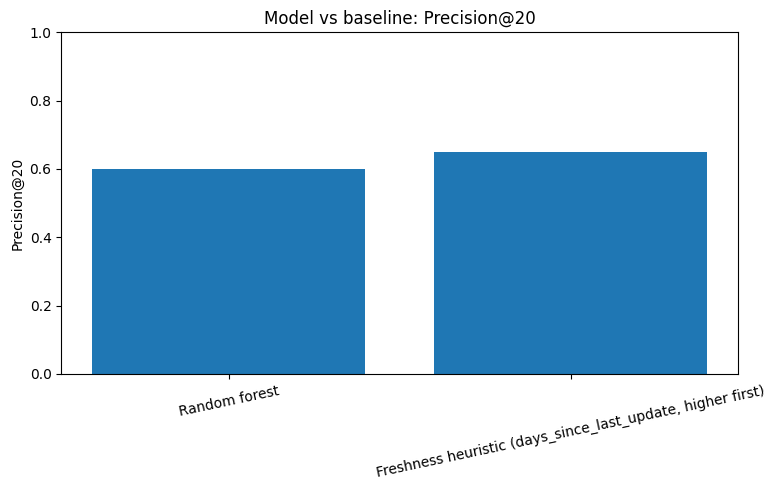

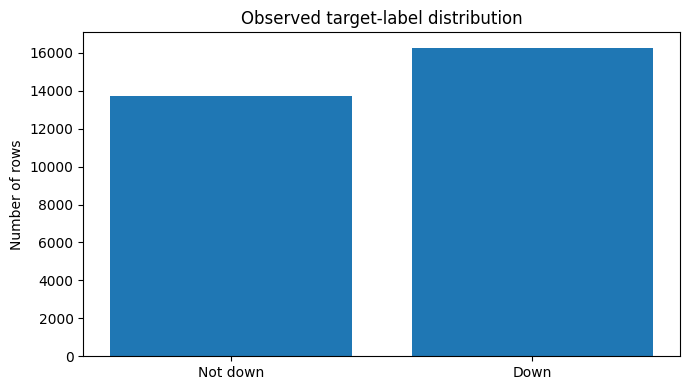


ARTIFACTS
- label_distribution.png
- model_vs_baseline_metrics.csv
- precision_at_k.png


In [21]:
# Save the results table.
metrics_path = OUTPUT_DIR / "model_vs_baseline_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

# Chart 1: precision at K.
precision_col = f"Precision@{k_eval}"

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    metrics_df["Method"],
    metrics_df[precision_col]
)
ax.set_title(f"Model vs baseline: Precision@{k_eval}")
ax.set_ylabel(f"Precision@{k_eval}")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", labelrotation=12)
fig.tight_layout()

precision_chart_path = OUTPUT_DIR / "precision_at_k.png"
fig.savefig(precision_chart_path, dpi=160)
plt.show()
plt.close(fig)

# Chart 2: label distribution.
label_counts = [
    int((y == 0).sum()),
    int((y == 1).sum())
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["Not down", "Down"], label_counts)
ax.set_title("Observed target-label distribution")
ax.set_ylabel("Number of rows")
fig.tight_layout()

label_chart_path = OUTPUT_DIR / "label_distribution.png"
fig.savefig(label_chart_path, dpi=160)
plt.show()
plt.close(fig)

# Chart 3: feature importance, when supported by the installed sklearn version.
importance_chart_path = OUTPUT_DIR / "feature_importance.png"

try:
    fitted_preprocessor = final_model.named_steps["preprocess"]
    transformed_names = fitted_preprocessor.get_feature_names_out()
    importances = final_model.named_steps["classifier"].feature_importances_

    importance_df = pd.DataFrame({
        "Feature": transformed_names,
        "Importance": importances
    })

    importance_df = importance_df.sort_values(
        "Importance", ascending=False
    ).head(15)

    fig, ax = plt.subplots(figsize=(9, 6))
    plot_df = importance_df.sort_values("Importance", ascending=True)

    ax.barh(plot_df["Feature"], plot_df["Importance"])
    ax.set_title("Random forest: top feature importances")
    ax.set_xlabel("Model feature importance")
    fig.tight_layout()

    fig.savefig(importance_chart_path, dpi=160)
    plt.show()
    plt.close(fig)

    importance_df.to_csv(
        OUTPUT_DIR / "feature_importance.csv",
        index=False
    )

except Exception as feature_plot_error:
    warnings.warn(
        "Feature-importance chart could not be generated in this environment: "
        f"{type(feature_plot_error).__name__}"
    )

print("\nARTIFACTS")
for path in sorted(OUTPUT_DIR.glob("*")):
    print("-", path.name)

## 5. Limitations

The target is historical, not a future guarantee. Client-held-out validation is preferred, but a row-split fallback is explicitly recorded if a valid grouped split cannot be created. Feature timing is not fully established by the column names alone. The freshness baseline is intentionally simple, and model scores are not calibrated probabilities. Human review and measurement in a new time window are required before drawing conclusions about whether a content change helped.

## 6. Ranked recommendations

1. Verify the decline label against the correct impression window and data coverage.
2. Inspect the highest-ranked pages for stale facts, inaccurate comparisons, missing coverage, weak search-intent fit, and broken internal links.
3. Make only changes supported by the manual audit.
4. Record the issue and change for each reviewed page.
5. Re-measure in a future window that was not used to construct the current target or select model features.

In [22]:
# Refit a fresh copy on all labeled data after held-out evaluation.
final_model = clone(model)
final_model.fit(X, y)

# Score all rows, including rows that may not have a usable target label.
df_all = df.reset_index(drop=True).copy()
X_all = df_all[FEATURES].copy()

all_scores = score_positive_class(final_model, X_all)

queue = pd.DataFrame()

if "content_id" in df_all.columns:
    queue["content_id"] = df_all["content_id"].astype("string")

# Include only non-identifying metadata useful for private manual review.
for col in [
    "content_type",
    "main_intent",
    "days_since_last_update",
    "content_age_days"
]:
    if col in df_all.columns:
        queue[col] = df_all[col]

queue["model_review_score"] = all_scores

def action_category(row):
    raw_days = row.get("days_since_last_update", np.nan)
    days_since_update = pd.to_numeric(
        pd.Series([raw_days]), errors="coerce"
    ).iloc[0]

    if pd.notna(days_since_update) and days_since_update >= 180:
        return "Freshness audit"

    content_type = str(row.get("content_type", "")).lower()

    if "comparison" in content_type:
        return "Comparison audit"

    if "keyword" in content_type:
        return "Intent and coverage audit"

    return "General content audit"

ACTION_GUIDANCE = {
    "Freshness audit": (
        "Verify current facts, dates, intent, and internal links before deciding "
        "whether an update is needed."
    ),
    "Comparison audit": (
        "Check whether comparisons, evaluation criteria, and recommendations "
        "remain accurate and useful."
    ),
    "Intent and coverage audit": (
        "Review search-intent fit, missing subtopics, title clarity, and useful "
        "internal links."
    ),
    "General content audit": (
        "Check factual accuracy, usefulness, intent fit, and internal links. "
        "Make changes only when the review provides evidence."
    )
}

queue["action_category"] = queue.apply(action_category, axis=1)
queue["recommended_action"] = queue["action_category"].map(ACTION_GUIDANCE)

queue = queue.sort_values(
    "model_review_score",
    ascending=False,
    kind="stable"
).reset_index(drop=True)

queue.insert(0, "priority_rank", np.arange(1, len(queue) + 1))

top20 = queue.head(min(TOP_K, len(queue))).copy()

# This file is for internal triage. Do not commit it to a public repository.
private_queue_path = OUTPUT_DIR / "review_queue_INTERNAL_DO_NOT_PUBLISH.csv"
top20.to_csv(private_queue_path, index=False)

action_summary = (
    top20["action_category"]
    .value_counts()
    .rename_axis("Action category")
    .reset_index(name="Count in top-20")
)

action_summary_path = OUTPUT_DIR / "top20_action_summary.csv"
action_summary.to_csv(action_summary_path, index=False)

print("Review queue created.")
print("Rows scored:", len(queue))
print("Top-20 rows:", len(top20))
print("Private queue saved to:", private_queue_path.resolve())

print("\nAction summary — top 20:")
print(action_summary.to_string(index=False))

print("\nTop-10 scores and action categories (no IDs shown):")
print(
    top20[["priority_rank", "model_review_score", "action_category"]]
    .head(10)
    .round(4)
    .to_string(index=False)
)

Review queue created.
Rows scored: 30000
Top-20 rows: 20
Private queue saved to: /content/capstone_artifacts/review_queue_INTERNAL_DO_NOT_PUBLISH.csv

Action summary — top 20:
          Action category  Count in top-20
Intent and coverage audit               20

Top-10 scores and action categories (no IDs shown):
 priority_rank  model_review_score           action_category
             1              0.9770 Intent and coverage audit
             2              0.9755 Intent and coverage audit
             3              0.9745 Intent and coverage audit
             4              0.9684 Intent and coverage audit
             5              0.9683 Intent and coverage audit
             6              0.9674 Intent and coverage audit
             7              0.9672 Intent and coverage audit
             8              0.9665 Intent and coverage audit
             9              0.9659 Intent and coverage audit
            10              0.9656 Intent and coverage audit


## 7. Artifacts the paper embeds

The notebook generates a model-versus-baseline metrics table, a Precision@K comparison chart, a target-distribution chart, and a feature-importance chart when supported by the installed environment. It also generates a top-20 review queue and an aggregate action summary. The queue containing page identifiers is an internal artifact and must not be included in the public paper or public repository. The published page should contain only public-safe charts, aggregate tables, methods, limitations, and recommendations.

In [23]:
def markdown_table(frame):
    """Create a Markdown table without requiring the optional tabulate package."""
    safe_frame = frame.copy().fillna("")
    headers = [str(c) for c in safe_frame.columns]

    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |"
    ]

    for _, row in safe_frame.iterrows():
        values = [str(row[col]).replace("|", "\\|") for col in safe_frame.columns]
        lines.append("| " + " | ".join(values) + " |")

    return "\n".join(lines)


metrics_for_paper = metrics_df.copy().round(3)
metrics_table_md = markdown_table(metrics_for_paper)
actions_table_md = markdown_table(action_summary)

positive_count = int(y.sum())
negative_count = int((y == 0).sum())
labeled_rows = len(y)
all_rows = len(df)
client_count = int(df["client_id"].nunique())

feature_list_md = "\n".join([f"- `{feature}`" for feature in FEATURES])

paper_md = f"""# Can historical content signals help prioritize pages for review?

## 1. Title + Abstract

Can content metadata and measurements from the preceding 30-day period help prioritize pages whose latest 30-day impressions declined by more than 20%? This analysis uses the public anonymized FlyRank starter CSV, which contains {all_rows:,} rows and {len(df.columns)} columns as loaded in this run. A random forest with missing-value handling and categorical encoding was compared with a freshness-first heuristic using the same test split: {SPLIT_NAME}. On the held-out test set, Precision@{k_eval} was {model_precision_k:.3f} for the model and {baseline_precision_k:.3f} for the baseline, against a positive-label rate of {test_base_rate:.3f}. The output is a decision-support review queue, not a claim about search-engine algorithms or a guarantee of future performance.

## 2. Introduction / Problem

Content teams need a practical way to choose which pages deserve human attention first. Reviewing every page equally is inefficient, while automatically rewriting pages based on a score risks making unsupported changes.

This work tests whether metadata and preceding-window measurements can help rank pages associated with an observed decline. The intended decision is which pages a reviewer should investigate first—not which pages should be automatically rewritten or which pages Google will rank differently.

## 3. Data

**Source:** {DATA_SOURCE}.

**Rows loaded:** {all_rows:,}. **Columns loaded:** {len(df.columns)}. **Distinct client groups:** {client_count}. **Rows with recognized target categories:** {labeled_rows:,}.

The starter data dictionary describes one row per content item. Performance summaries include trailing-90-day metrics and fields comparing the latest 30 days with the preceding 30-day period. The CSV's column names describe windows, but do not by themselves establish the absolute calendar start and end dates of this export; those dates should be confirmed from release documentation before publication.

The binary target is `1` when `trend_direction == "down"` and `0` for the other recognized categories. Target counts in the modeled rows were:

- Observed down label: {positive_count:,} ({positive_count / labeled_rows:.1%})
- Other recognized direction labels: {negative_count:,} ({negative_count / labeled_rows:.1%})

The modeling feature set excludes identifiers, the target and its derived percentage, recent outcome metrics, trailing-90-day outcome summaries that overlap the target period, and derived performance rates. No client names, domains, URLs, titles, or private queries are included in this paper.

## 4. Methodology

The target identifies a historical direction category rather than a future outcome. The model uses selected content metadata, keyword context, and previous-30-day measurements. Missing numeric data are imputed with the training median and missing categorical values receive an explicit missing category. Categorical fields are one-hot encoded.

Selected features:

{feature_list_md}

The baseline prioritizes pages with the most days since last update, using `days_since_last_update` when available and `content_age_days` as a fallback. The model and baseline are evaluated on the same held-out rows. The selected split was **{SPLIT_NAME}**. The random seed was {SEED}. IDs are used for grouping only and never as model features.

The model uses a Random Forest with 300 trees, a minimum leaf size of 5, and balanced subsampling class weights. The split and model settings are designed to provide a repeatable comparison, not to prove that this model is the best possible model.

## 5. Results (vs baseline)

The test-set positive-label rate was **{test_base_rate:.3f}**. This base rate provides context for interpreting Precision@{k_eval}.

{metrics_table_md}

The results above were measured on the same held-out test set. They should be interpreted as retrospective ranking performance against the observed target label. They do not show that content changes caused a traffic improvement.

### Artifacts the paper embeds

**Precision at K**

![Model vs baseline Precision at K](precision_at_k.png)

Caption: Precision@{k_eval} compares how many of the highest-ranked test pages carry the observed down label for the model and the freshness baseline.

**Target distribution**

![Target distribution](label_distribution.png)

Caption: The chart shows the count of modeled rows labeled down compared with other recognized directions.

**Feature importance**

If generated, `feature_importance.png` shows features used by the fitted random forest. Feature importance is a model diagnostic, not causal evidence.

## 6. Limitations & honest framing

- The target is an observed historical direction category, not a confirmed future decline.
- A client-held-out split was used only if the available groups allowed both classes in train and test. Otherwise, the notebook explicitly records a stratified row-split fallback.
- The raw snapshot does not itself establish the absolute calendar end date of the measurement windows.
- Metadata timestamp alignment should be verified before claiming that every feature would have been available at decision time.
- The freshness baseline is a simple heuristic. It is a reference point, not a claim that freshness alone causes traffic decline.
- Scores are for prioritization, not calibrated probabilities. A human should inspect each page and its measurement context.
- The dataset is an anonymized teaching/sample release. Results may not generalize to other clients, sites, time periods, or content systems.

## 7. Ranked recommendations

1. **Verify the signal first.** Check the relevant impression trend, measurement window, and data coverage before changing a page.
2. **Review freshness and accuracy.** For high-ranked pages, verify facts, dates, product or comparison details, broken links, and whether the content is still useful.
3. **Check intent and coverage.** Inspect whether the page answers the likely search intent and covers the important questions without adding unnecessary text.
4. **Make evidence-based changes.** Do not rewrite a page only because it has a high score. Record the issue found and the change made.
5. **Measure after the change.** Evaluate subsequent performance in a new window, and keep that future window separate from feature development and model selection.

The top-20 model queue is saved as a local internal artifact for review. Page identifiers from that queue should not be published. The public paper uses aggregate results and action categories instead.

Action categories represented among the top-ranked pages:

{actions_table_md}

## 8. Reproducibility

The notebook runs from top to bottom in this order: data loading, target definition and leakage checks, split creation, model training, baseline comparison, review queue creation, chart generation, and report generation.

- Random seed: `{SEED}`
- Selected validation: `{SPLIT_NAME}`
- scikit-learn version: `{sklearn.__version__}`
- Model settings: 300 trees, minimum leaf size 5, balanced subsampling weights
- Output folder: `capstone_artifacts/`
- Main metrics file: `model_vs_baseline_metrics.csv`
- Charts: `precision_at_k.png`, `label_distribution.png`, and, when supported, `feature_importance.png`

Before publishing, replace this sentence with a verified public repository URL and notebook link. Confirm that the links open without account access. Do not include the internal review queue CSV in the public repository.

## 9. Acknowledgments & data credit

This project uses the anonymized FlyRank ML Internship starter dataset for an educational decision-support exercise. Thanks to FlyRank for providing the dataset and project materials.

Data and project credit: [FlyRank](https://flyrank.ai).

This work is an independent capstone analysis and should not be presented as an official statement of FlyRank's products or as a guarantee of search-performance outcomes.
"""

paper_path = OUTPUT_DIR / "capstone_paper.md"
paper_path.write_text(paper_md, encoding="utf-8")

print("Paper draft saved to:", paper_path.resolve())
print("\nPaper preview:\n")
print(paper_md[:5000])

Paper draft saved to: /content/capstone_artifacts/capstone_paper.md

Paper preview:

# Can historical content signals help prioritize pages for review?

## 1. Title + Abstract

Can content metadata and measurements from the preceding 30-day period help prioritize pages whose latest 30-day impressions declined by more than 20%? This analysis uses the public anonymized FlyRank starter CSV, which contains 30,000 rows and 44 columns as loaded in this run. A random forest with missing-value handling and categorical encoding was compared with a freshness-first heuristic using the same test split: Client-held-out GroupShuffleSplit. On the held-out test set, Precision@20 was 0.600 for the model and 0.650 for the baseline, against a positive-label rate of 0.511. The output is a decision-support review queue, not a claim about search-engine algorithms or a guarantee of future performance.

## 2. Introduction / Problem

Content teams need a practical way to choose which pages deserve human attent

In [24]:
demo_outline = f"""# Five-minute demo outline

**0:00–0:40 — The problem**
Explain why content teams need a prioritized human-review queue.

**0:40–1:20 — The data and label**
Show the anonymized dataset dimensions and explain that the target is trend_direction == 'down'.

**1:20–2:00 — Leakage checks**
Show the excluded target-derived, latest-30-day, trailing-90-day, and identifier fields.

**2:00–3:00 — Model and baseline**
Explain the random forest and the freshness-first heuristic. Both were evaluated on the same test split.

**3:00–4:00 — Results**
Show the Precision@{k_eval} chart and metrics table. The measured comparison was model = {model_precision_k:.3f} vs baseline = {baseline_precision_k:.3f}, with test-set positive-label rate = {test_base_rate:.3f}.

**4:00–4:35 — Review queue**
Show only aggregate action categories or anonymized example rows. Do not show private identifiers or raw client data.

**4:35–5:00 — Limitations**
Explain the validation split, historical label, feature-timing assumptions, and why human review is required.
"""

social_post = f"""I built a content-review prioritization workflow using the public anonymized FlyRank ML internship starter dataset.

The project compares a random-forest model with a transparent freshness-first baseline on the same held-out test set. Precision@{k_eval} was {model_precision_k:.3f} for the model and {baseline_precision_k:.3f} for the baseline, against a test-set positive-label rate of {test_base_rate:.3f}.

The target is an observed historical decline label, so this is decision support for manual review—not a claim about search-engine algorithms or a guarantee of future traffic. The notebook also generates charts, a ranked review queue, and a reproducible paper draft.
"""

employer_summary = (
    "I built an end-to-end content-review prioritization workflow using an "
    "anonymized dataset, with leakage checks, preprocessing, client-grouped "
    "validation where possible, and a reproducible ranking model. "
    f"On the held-out test set, the model achieved Precision@{k_eval} of "
    f"{model_precision_k:.3f}, compared with {baseline_precision_k:.3f} "
    f"for the freshness-first baseline, against a positive-label rate of "
    f"{test_base_rate:.3f}. "
    "The result supports human review prioritization and is framed as "
    "retrospective decision support rather than a guarantee of future traffic gains."
)

ml12_path = OUTPUT_DIR / "ml12_demo_social_employer.md"
ml12_content = (
    demo_outline
    + "\n\n---\n\n"
    + "## Social post\n\n"
    + social_post
    + "\n\n---\n\n"
    + "## Three-sentence employer summary\n\n"
    + employer_summary
    + "\n"
)

ml12_path.write_text(ml12_content, encoding="utf-8")

print("ML-12 materials saved to:", ml12_path.resolve())
print("\nSOCIAL POST\n")
print(social_post)
print("\nEMPLOYER SUMMARY\n")
print(employer_summary)

ML-12 materials saved to: /content/capstone_artifacts/ml12_demo_social_employer.md

SOCIAL POST

I built a content-review prioritization workflow using the public anonymized FlyRank ML internship starter dataset.

The project compares a random-forest model with a transparent freshness-first baseline on the same held-out test set. Precision@20 was 0.600 for the model and 0.650 for the baseline, against a test-set positive-label rate of 0.511.

The target is an observed historical decline label, so this is decision support for manual review—not a claim about search-engine algorithms or a guarantee of future traffic. The notebook also generates charts, a ranked review queue, and a reproducible paper draft.


EMPLOYER SUMMARY

I built an end-to-end content-review prioritization workflow using an anonymized dataset, with leakage checks, preprocessing, client-grouped validation where possible, and a reproducible ranking model. On the held-out test set, the model achieved Precision@20 of 0.60

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
